## Mini Project 2: Training and Evaluation Practices

Ethan, Anto, and Marc

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import itertools
import sklearn

%pip install ucimlrepo
from ucimlrepo import fetch_ucirepo

SEED = 2026
rng = np.random.default_rng(seed=SEED)

Note: you may need to restart the kernel to use updated packages.


In [2]:
spambase = fetch_ucirepo(id=94)
# print(spambase.variables) # variable information, potentially informs cleanup decisions
df = spambase.data
x = df.features
y = df.targets
x

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,word_freq_conference,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.0,0.000,0.000,0.0,0.778,0.000,0.000,3.756,61,278
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.0,0.000,0.132,0.0,0.372,0.180,0.048,5.114,101,1028
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.0,0.010,0.143,0.0,0.276,0.184,0.010,9.821,485,2259
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.0,0.000,0.137,0.0,0.137,0.000,0.000,3.537,40,191
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.0,0.000,0.135,0.0,0.135,0.000,0.000,3.537,40,191
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4596,0.31,0.00,0.62,0.0,0.00,0.31,0.00,0.00,0.00,0.00,...,0.0,0.000,0.232,0.0,0.000,0.000,0.000,1.142,3,88
4597,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.00,...,0.0,0.000,0.000,0.0,0.353,0.000,0.000,1.555,4,14
4598,0.30,0.00,0.30,0.0,0.00,0.00,0.00,0.00,0.00,0.00,...,0.0,0.102,0.718,0.0,0.000,0.000,0.000,1.404,6,118
4599,0.96,0.00,0.00,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.0,0.000,0.057,0.0,0.000,0.000,0.000,1.147,5,78


# Data Preproccessing



In [3]:
class Standardizer:
  def fit(self, data):
    """
    Calculates and stores the mean and standard deviation of the provided data.

    Parameters:
    data: NumPy array of data to fit
    """
    self.mean = np.mean(data, axis=0, keepdims=True)
    self.std = np.std(data, axis=0, keepdims=True)
    self.std[self.std == 0] = 1.0 # guard from zero to avoid issues down the line


  def standardize(self, data):
    """
    Standardizes the provided data using the stored mean and standard deviation.

    Parameters:
    data: NumPy array of data to standardize

    Returns:
    s_data: NumPy array of standardized data
    """
    s_data = (data - self.mean) / self.std

    return s_data

In [4]:
train_frac = 0.05 # fraction of data to be used for training.

x_ar = x.to_numpy();
y_ar = np.squeeze(y.to_numpy())

indices = rng.permutation(x_ar.shape[0])

split = int(x_ar.shape[0] * train_frac)

x_train = x_ar[indices[:split]]
y_train = y_ar[indices[:split]]
x_test = x_ar[indices[split:]]
y_test = y_ar[indices[split:]]

In [5]:
sr = Standardizer()

sr.fit(x_train)
x_train = sr.standardize(x_train)
x_test = sr.standardize(x_test)
x_train

array([[-0.35783699, -0.18369221, -0.54338653, ..., -0.08874086,
        -0.29998628, -0.48914258],
       [-0.35783699, -0.18369221, -0.54338653, ..., -0.09416744,
        -0.31533938, -0.52996449],
       [-0.35783699, -0.18369221, -0.54338653, ..., -0.08514604,
        -0.19251456, -0.35707168],
       ...,
       [ 1.78504413, -0.18369221, -0.54338653, ..., -0.09551836,
        -0.29998628, -0.39068973],
       [-0.35783699, -0.18369221,  1.36135621, ..., -0.111821  ,
        -0.32301594, -0.47953742],
       [-0.35783699, -0.18369221, -0.54338653, ..., -0.07752135,
        -0.25392697, -0.48914258]], shape=(230, 57))

# Task 1: Logistic Regression with SGD

In [6]:
class StochasticGradientDescent:

    def __init__(self, batch_size=16, lr=0.1, num_epochs=200, logging=True):
        """
        Initializes StochasticGradientDescent optimizer.

        This class implements minibatch stochastic gradient descent.
        """

        self.batch_size = batch_size
        self.lr = lr
        self.epochs = num_epochs
        self.logging = logging

        if self.logging:
          self.w_log = []

    def run(self, gradient_fn, x, y, w):
        """
        Runs stochastic gradient descent.

        Parameters:
        gradient: function that computes gradient given (x, y, w),
                      returns gradient with same shape as w
        x: NumPy array of input features, shape (N, D)
        y: NumPy array of target values, shape (N,)
        w: NumPy array of initial weights, shape (D,)

        Returns:
        w:  NumPy array of final weights, shape (D,)
        """
        grad = np.inf

        for epoch in range(self.epochs):
          if self.logging:
            self.w_log.append(w)

          indices = rng.permutation(x.shape[0]) # shuffles indices

          for batch in itertools.batched(indices, self.batch_size):
            batch = list(batch)
            grad = gradient_fn(x[batch], y[batch], w)
            w = w - self.lr * grad

        if self.logging:
            self.w_log.append(w)

        return w

In [7]:
class LogisticRegression:

    def __init__(self, lam=10**(-2), add_constant=True, init_scale=0.0):
        """
        Initializes LogisticRegression classifier.

        This class implements logistic regression.

        Parameters:
        lam: regularization strength, if 0, no regularization applied
        add_constant: if True, adds constant to weights
        init_scale: initial weight scale
        """

        self.lam = lam
        self.add_constant = add_constant
        self.init_scale = init_scale

    def fit(self, x, y, optimizer):
        """
        Fit the logistic regression model using the provided optimizer.

        Parameters:
        x: NumPy array of features, shape (N, D)
        y: NumPy array of target, must be binary, shape (N,)
        optimizer: optimizer with a run() function taking (gradient_fn, x, y, w)
                    and returning optimized weights
        """

        if self.add_constant:
          x = np.column_stack([np.ones(x.shape[0]), x])
          # keep constant term out front for convenience

        if self.init_scale > 0:
            self.w = rng.normal(0, self.init_scale, x.shape[1]) # initialize weights to init_scale, set to 0 by default
        else:
            self.w = np.zeros(x.shape[1]) # normal


        self.w = optimizer.run(self.get_gradient_fn(), x, y, self.w) # optimize weights

    def predict(self, x):
        """
        Predict class probabilities for input x.

        Parameters:
        x: NumPy array of features, shape (N,) or (N, D)

        Returns:
        y_hat: NumPy array of predicted probabilities, shape (N,)
        """

        if self.add_constant:
            x = np.column_stack([np.ones(x.shape[0]), x])

        y_hat = LogisticRegression.logistic(np.dot(x, self.w))

        return y_hat

    def get_gradient_fn(self):
      """
      Generates a gradient function with regularization lam.
      """

      def gradient_fn(x, y, w):
        y_hat = LogisticRegression.logistic(np.dot(x, w))

        grad = np.dot(x.T, y_hat - y) / x.shape[0]

        reg = self.lam * w
        if self.add_constant:
          reg[0] = 0 # excluding bias from regularization
        grad += reg # using lambda/2 convention

        return grad

      return gradient_fn

    def calculate_crossentropy(self, x, y, w):
      if self.add_constant:
        x = np.column_stack([np.ones(x.shape[0]), x])

      z = np.dot(x, w)
      #ce = np.mean(y * np.log1p(np.exp(-z)) + (1-y) * np.log1p(np.exp(z))) (causes overflow)
      ce = np.mean(y * np.logaddexp(0, -z) + (1 - y) * np.logaddexp(0, z))

      return ce


    def calculate_accuracy(self, x, y, w):
      if self.add_constant:
        x = np.column_stack([np.ones(x.shape[0]), x])

      y_hat = LogisticRegression.logistic(np.dot(x, w))
      y_pred = y_hat > 0.5

      acc = np.mean(y_pred == y)

      return acc

    @staticmethod
    def logistic(z):
      """
      Implements the logistic function.
      """
      return 1. / (1 + np.exp(-z))

In [8]:
l = LogisticRegression()
sgd = StochasticGradientDescent(batch_size=16, lr=0.1, num_epochs=200, logging=True)
l.fit(x_train, y_train, sgd)

cross_entropies = [l.calculate_crossentropy(x_train, y_train, w) for w in sgd.w_log]
accuracies = [l.calculate_accuracy(x_train, y_train, w) for w in sgd.w_log]

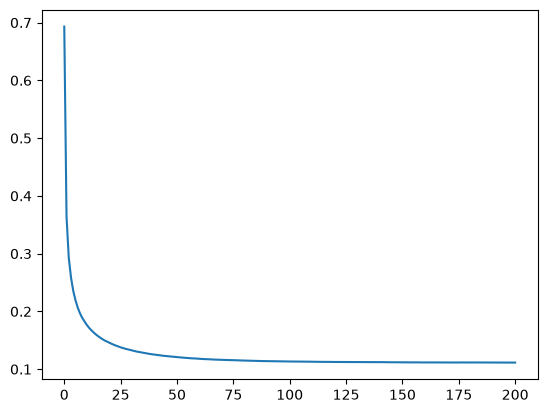

In [9]:
plt.plot(range(201), cross_entropies)

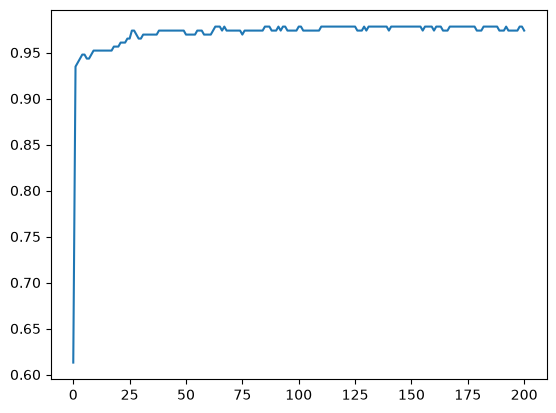

In [10]:
plt.plot(range(201), accuracies)

# Task 2: Hyperparameter Tuning with K-Fold Cross-Validation

Across K-folds of size K<=N, cross-validate. Cross-validate by training on K-1 folds, then evaluating on remaining validation fold.

## K-Folding

In [11]:
# k-folding
def kfold(n, k, rng):
  """
  Lazily generates indices that split a numpy array into K folds, K-1 for training and 1 for validation.
  Computes pairs of indices rather than actual

  Parameters:
  n: number of samples
  k: number of desired folds
  rng: numpy random generator

  Returns:
  (train, validate) index pairs for each of K possible fold arrangements
  """
  idx = rng.permutation(n) # permute the order before folding
  folds = np.array_split(idx, k)

  for i in range(k): # exclusive for k
    validate = folds[i]

    train_parts = []
    for j in range(k):
      if j != i:
        train_parts.append(folds[j])
    train = np.concatenate(train_parts)

    yield train, validate


## Cross Validation (CV)

Problem to consider:

If we standardize X before performing k-fold cross-validation, then the training set (k-1 folds + validation fold) are all standardized by mean and standard deviation.

To fix: derive mean and standard deviation from x[train] only, then standardize x[train] and x[validate] both. Repeat for every fold arrangement.

Below is a not-good version and then a good shadowed version of cross_validate() to fix this.

In [12]:
# cross validation after standardizing x: bad, see below
def bad_cross_validate(x, y, k_folds, learn_rate=0.1, lam=0.1, batch_size=16, epochs=200, init_scale=0.0):
  """
  Perform k-fold cross-validation with stochastic gradient descent

  Parameters:
  x:          np.ndarray, shape (N, D), instances
  y:          np.ndarray, shape (N,) binary training labels
  k_folds:    list of tuples (train, validate) indices that split the train set from validate
  init_scale: float, initial weight scale

  Hyperparameters to tune:
  learn_rate: learning rate for each step in SGD e.x. {1, 0.1, 0.001, 0.0001, 0.00001}
  lam:        lambda, regularization penalty e.x. {0.01, 0.1, 0.5}
  batch_size: size of each minibatch in SGD e.x. {1, 16, 64}
  epochs:     number of full passes over the training folds e.x. {50, 100, 150, 200}

  Returns: {ce_mean, ce_stddev, acc_mean, acc_stddev}, cross-entropy and accuracy metrics across k-fold arrangements
  """
  cross_entropies = []
  accuracies = []

  for tr_idx, val_idx in k_folds:
    # data leaking occurs here, where validation and training sets are standardized beforehand
    model = LogisticRegression(lam, init_scale=init_scale)
    w = StochasticGradientDescent(batch_size, learn_rate, epochs, logging=False)
    model.fit(x[tr_idx], y[tr_idx], w)

    # metrics
    ce = model.calculate_crossentropy(x[val_idx], y[val_idx], model.w)
    acc = model.calculate_accuracy(x[val_idx], y[val_idx], model.w)
    cross_entropies.append(ce)
    accuracies.append(acc)

  # mean and standard deviations
  ce_mean = np.mean(cross_entropies)
  ce_stddev = np.std(cross_entropies)
  acc_mean = np.mean(accuracies)
  acc_stddev = np.std(accuracies)

  return {'ce_mean': ce_mean, 'ce_stddev': ce_stddev, 'acc_mean': acc_mean, 'acc_stddev': acc_stddev}

# cross validation properly ~ x[tr_idx] standardization generates mean and stddev, used to standardize s[val_idx]
def cross_validate(x, y, k_folds, learn_rate=0.1, lam=0.1, batch_size=16, epochs=200, init_scale=0.0):
  """
  Perform k-fold cross-validation with stochastic gradient descent

  Parameters:
  x:          np.ndarray, shape (N, D), instances, **NOT YET STANDARDIZED**
  y:          np.ndarray, shape (N,) binary training labels
  k_folds:    list of tuples (train, validate) indices that split the train set from validate
  init_scale: float, initial weight scale

  Hyperparameters to tune:
  learn_rate: learning rate for each step in SGD e.x. {1, 0.1, 0.001, 0.0001, 0.00001}
  lam:        lambda, regularization penalty e.x. {0.01, 0.1, 0.5}
  batch_size: size of each minibatch in SGD e.x. {1, 16, 64}
  epochs:     number of full passes over the training folds e.x. {50, 100, 150, 200}

  Returns: {ce_mean, ce_stddev, acc_mean, acc_stddev}, cross-entropy and accuracy metrics across k-fold arrangements
  """
  cross_entropies = []
  accuracies = []

  for tr_idx, val_idx in k_folds:
    # fit standardizer for every fold arrangement without validation set in consideration
    s = Standardizer()
    s.fit(x[tr_idx])

    x_train = s.standardize(x[tr_idx])
    x_validate = s.standardize(x[val_idx]) # using same parameters as train set
    y_train = y[tr_idx]
    y_validate = y[val_idx]

    model = LogisticRegression(lam, init_scale=init_scale)
    w = StochasticGradientDescent(batch_size, learn_rate, epochs, logging=False)
    model.fit(x_train, y_train, w)

    # metrics
    ce = model.calculate_crossentropy(x_validate, y_validate, model.w)
    acc = model.calculate_accuracy(x_validate, y_validate, model.w)

    cross_entropies.append(ce)
    accuracies.append(acc)

  # mean and standard deviations
  ce_mean = np.mean(cross_entropies)
  ce_stddev = np.std(cross_entropies)
  acc_mean = np.mean(accuracies)
  acc_stddev = np.std(accuracies)

  return {'ce_mean': ce_mean, 'ce_stddev': ce_stddev, 'acc_mean': acc_mean, 'acc_stddev': acc_stddev}

In [13]:
# test
from tqdm.notebook import tqdm # progress bars and reports

x_train = x_ar[indices[:split]]
y_train = y_ar[indices[:split]]
x_test = x_ar[indices[split:]]
y_test = y_ar[indices[split:]]

(N, _) = np.shape(x_train)

k = 5
folds = list(kfold(N, k, rng))

batch_sizes = [1, 16, 64]
lrs = [1, 1e-1, 1e-2, 1e-3, 1e-4]
epochs = [50, 150, 200]
init_scales = [0, 0.01, 0.1, 1]

grid = list(itertools.product(batch_sizes, lrs, epochs, init_scales))

rows = []
for B, lr, ep, scale in tqdm(grid, desc="hyperparameter search"):
    result = cross_validate(x_train, y_train, folds, learn_rate=lr, lam=0.01, batch_size=B, epochs=ep, init_scale=scale)
    rows.append({"B": B, "lr": lr, "epochs": ep, "init_scale": scale, **result})

results = pd.DataFrame(rows)
results.sort_values("ce_mean").reset_index(drop=True) # gives best configurations at top in terms of cross-entropy mean

hyperparameter search:   0%|          | 0/180 [00:00<?, ?it/s]

/var/folders/qh/s0s647n952jf6nrz8vrx8rcc0000gn/T/ipykernel_93683/1883909502.py:106: RuntimeWarning: overflow encountered in exp
  return 1. / (1 + np.exp(-z))


,B,lr,epochs,init_scale,ce_mean,ce_stddev,acc_mean,acc_stddev
0,16,1.0000,50,0.00,0.290729,0.161530,0.926087,0.057680
1,1,0.1000,200,1.00,0.294069,0.163610,0.921739,0.052535
2,1,0.1000,150,0.00,0.299541,0.170064,0.926087,0.057680
3,16,1.0000,150,0.01,0.300514,0.171546,0.921739,0.059296
4,16,1.0000,200,0.00,0.301773,0.165809,0.921739,0.059296
...,...,...,...,...,...,...,...,...
175,16,0.0001,200,1.00,3.618215,0.509905,0.543478,0.101966
176,64,0.0001,200,1.00,3.778225,1.316549,0.513043,0.082035
177,64,0.0010,150,1.00,4.359204,0.588380,0.395652,0.079459
178,16,0.0001,50,1.00,4.443559,3.124144,0.526087,0.086302


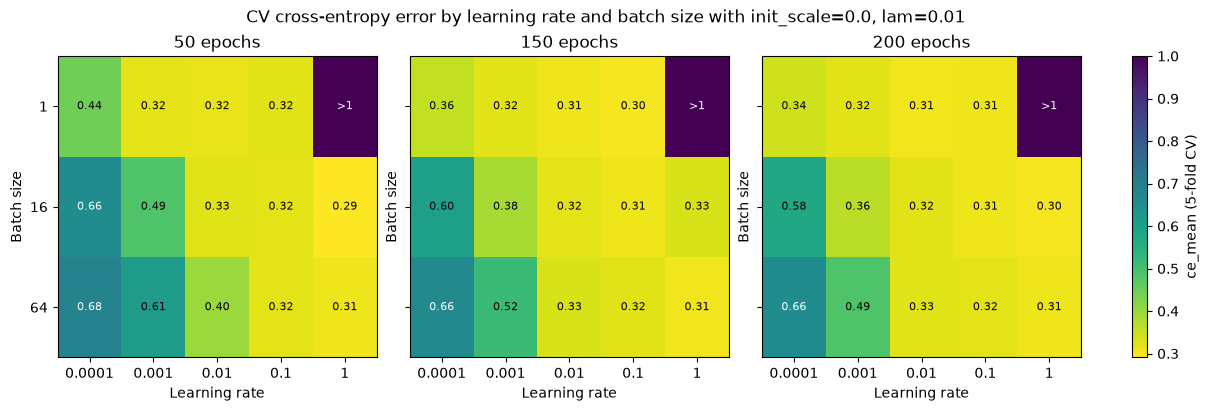

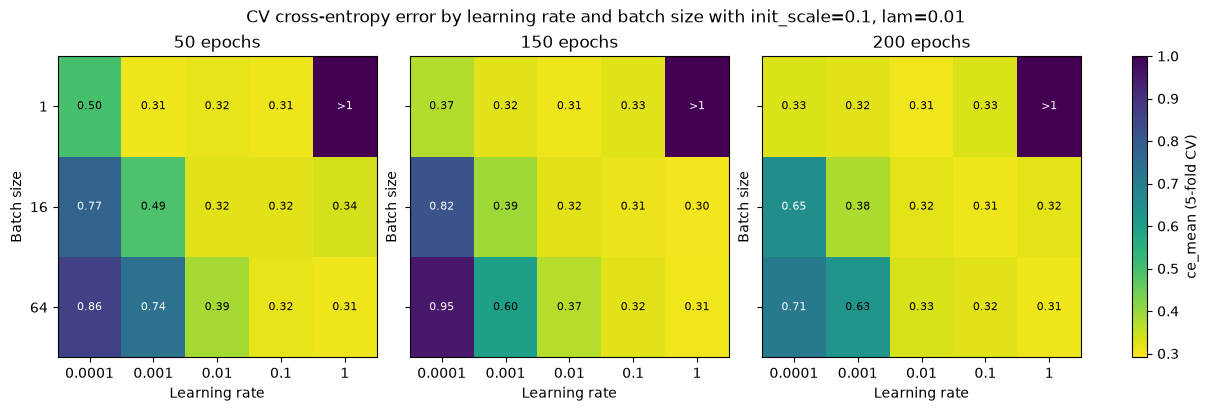

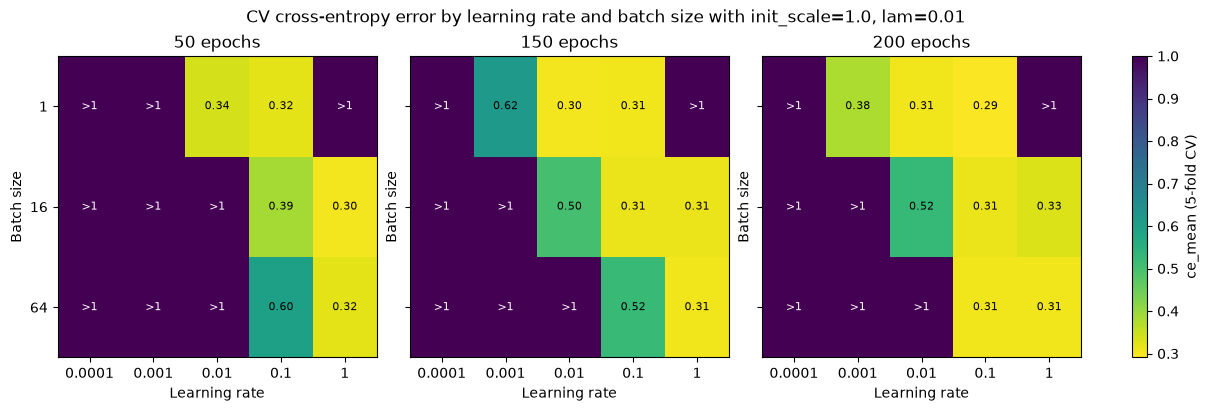

In [14]:
# plot results with a heatmap, since we cant plot easily in four dimensions
# https://www.geeksforgeeks.org/python/how-to-draw-2d-heatmap-using-matplotlib-in-python/

import matplotlib.colors as mcolors

def plot_heatmap(results, init_scale=0.0, quality_metric="ce_mean", save=None):
  df = results[results.init_scale == init_scale] # isolate when init_scale = given
  epoch_values = sorted(df.epochs.unique())
  n = len(epoch_values)
  fig, axs = plt.subplots(1, n, figsize=(4*n, 4), sharey=True, constrained_layout=True)
  axs = np.atleast_1d(axs) # arrays of at least 1D

  # define colour range
  normalized = mcolors.Normalize(vmin=results[quality_metric].min(), vmax=1.0) # define proper range of vals

  for ax, ep in zip(axs, epoch_values): # permute all pairs
    # rows = batch size, ascending
    # cols = learning rate, ascending
    grid = (df[df.epochs == ep].pivot_table(index="B", columns="lr", values=quality_metric).sort_index(axis=1))

    # reverse colours since lower CE => better result
    # low cross-entropy error = yellow, high cross-entropy error = purple
    render = ax.imshow(grid.values, cmap="viridis_r", norm=normalized, aspect="auto")

    # labels
    ax.set_xticks(range(len(grid.columns)))
    ax.set_xticklabels([f"{c:g}" for c in grid.columns])
    ax.set_yticks(range(len(grid.index)))
    ax.set_yticklabels([f"{r:g}" for r in grid.index])

    ax.set_ylabel("Batch size")
    ax.set_xlabel("Learning rate")
    ax.set_title(f"{ep} epochs")

    # label each square
    for i in range(grid.shape[0]):
      for j in range(grid.shape[1]):
        v = grid.values[i, j]
        txt = f">1" if v > 1 else f"{v:.2f}"
        ax.text(j, i, txt, ha="center", va="center", fontsize=8,
                color="white" if normalized(min(v, 1)) > 0.5 else "black")


  fig.suptitle(f"CV cross-entropy error by learning rate and batch size with init_scale={init_scale}, lam=0.01")
  fig.colorbar(render, ax=axs, label=f"{quality_metric} (5-fold CV)")

  if save is not None:
    fig.savefig(save, bbox_inches="tight") # bounding box tight, export as vector image
  plt.show()

# plot_heatmap(results, init_scale=0.0, quality_metric="ce_mean", save="fig_task2_heatmap_init0.pdf")
# plot_heatmap(results, init_scale=0.1, quality_metric="ce_mean", save="fig_task2_heatmap_init01.pdf")
# plot_heatmap(results, init_scale=1.0, quality_metric="ce_mean", save="fig_task2_heatmap_init1.pdf")
plot_heatmap(results, init_scale=0.0, quality_metric="ce_mean")
plot_heatmap(results, init_scale=0.1, quality_metric="ce_mean")
plot_heatmap(results, init_scale=1.0, quality_metric="ce_mean")

## Results

**Analysis of heatmaps**

- Left to right in a submap is ascending Learning Rate
- Top to bottom in a submap is ascending Batch Size
- Between submaps in a row is varying number of epochs
- Between submaps in a column is varying init_scale

With init_scale at 0.1: (ignoring runs with very large error >1)
1. Learning rate causes a change in CE of max ~0.5
2. Batch size causes a change in CE of max ~0.4
3. Number epochs of causes a change in CE of ~0.3

This gives us a ranking of measurable impact.

The weight initialization scale makes very little impact beyond causing divergence in error, as we see the exact same configuration (B, eps, lr) changes very little when varying init_scale.


In [15]:
def get_best_hyperparameters(results, init_scale=0.0, n_folds=5, logging=False):
  """
  Retrieve the best configuration found through cross validation

  Rules to pick the best:
  1. keep only the runs with given init_scale
  2. average ce_mean over epochs, giving a single estimate per (B, lr) cell
  3. score a cell by averaging it between its neighbours learning rates
  4. any cell within one SE is a tie
  5. finally we pick the largest B, then smallest lr (the fastest while also most convergent solution)
  6. for the chosen cell, use the epoch count with the lowest CE mean, done!
  See https://scikit-learn.org/stable/auto_examples/model_selection/plot_grid_search_refit_callable.html
  for the "one standard error" approach

  Parameters:
  results:        DataFrame of results post-CV
                  (columns B, lr, epochs, init_scale, ce_mean, ce_stddev, acc_mean, acc_stddev)
  init_scale: initialization scale to select within
  n_folds:    K used in cross validation, for the standard error

  Returns: {B, lr, epochs, init_scale}, best configuration
  """
  df = results[results.init_scale == init_scale] # satisfy (1)

  # (2) one row per B, one column per lr (ascending)
  cells = df.groupby(["B", "lr"]).ce_mean.mean().unstack("lr").sort_index(axis=1)
  stddevs = df.groupby(["B", "lr"]).ce_stddev.mean() # fold-to-fold stddev per cell

  # (3) mean of each cell and its lr neighbours, edge columns are excluded
  ties_resolved = cells.T.rolling(3, center=True, min_periods=3).mean().T # rolling = sliding window of 3, i.e. left + mid + right
  scores = ties_resolved.stack() # drops those excluded, indexed by (B, lr)

  # (4) one standard error approach
  B_best, lr_best = scores.idxmin()
  std_err = stddevs.loc[(B_best, lr_best)] / np.sqrt(n_folds)
  tied = scores[scores <= scores.min() + std_err]

  # (5) largest B and smallest lr, of those that tied in 1SE
  tied_df = tied.reset_index(name="score").sort_values(["B", "lr"], ascending=[False, True]) # B up, lr down
  B, lr = tied_df.iloc[0].B, tied_df.iloc[0].lr

  # (6) epoch count with the lowest ce_mean for the chosen (B, lr) panel
  panel = df[(df.B == B) & (df.lr == lr)]
  epochs = panel.loc[panel.ce_mean.idxmin(), "epochs"]

  if logging:
    chosen = panel[panel.epochs == epochs].iloc[0]
    print(f"{len(tied)} (B, lr) cells within one standard error of the best score")
    print(f"chosen: ce_mean={chosen.ce_mean:.3f}, ce_stddev={chosen.ce_stddev:.3f}, "
          f"acc_mean={chosen.acc_mean:.3f}")
  return {
      "B": int(B), "lr": float(lr), "epochs": int(epochs), "init_scale": float(init_scale)
  }

print(get_best_hyperparameters(results, logging=True))

5 (B, lr) cells within one standard error of the best score
chosen: ce_mean=0.319, ce_stddev=0.180, acc_mean=0.922
{'B': 64, 'lr': 0.1, 'epochs': 200, 'init_scale': 0.0}




# Task 3: Bias–Variance Trade-Off via λ Sweep (With K-Fold CV)

In [16]:
# cv helper that returns training metrics too
def cross_validate_with_train(x, y, k_folds, learn_rate=0.1, lam=0.1, batch_size=16, epochs=200, init_scale=0.0):
  """
  Perform k-fold cross-validation with stochastic gradient descent

  Parameters:
  x:          np.ndarray, shape (N, D), instances, **NOT YET STANDARDIZED**
  y:          np.ndarray, shape (N,) binary training labels
  k_folds:    list of tuples (train, validate) indices that split the train set
              from validate

  Hyperparameters to tune:
  learn_rate: learning rate for each step in SGD e.x. {1, 0.1, 0.001, 0.0001, 0.00001}
  lam:        lambda, regularization penalty e.x. {0.01, 0.1, 0.5}
  batch_size: size of each minibatch in SGD e.x. {1, 16, 64}
  epochs:     number of full passes over the training folds e.x. {50, 100, 150, 200}

  Returns: {val_ce_mean, val_ce_std, val_acc_mean, val_acc_std, tr_ce_mean,
            tr_ce_std, tr_acc_mean, tr_acc_std},
            cross-entropy and accuracy metrics across k-fold arrangements
  """
  # One list per metric; each list 1 val per fold
  metrics = {"val_ce": [], "val_acc": [], "tr_ce": [], "tr_acc": []}
  for tr_idx, val_idx in k_folds:

    # standardize using only this fold's training data (to avoid leakage)
    s = Standardizer()
    s.fit(x[tr_idx])
    s.std[s.std == 0] = 1.0 # avoid divide by zero
    xtr, xva = s.standardize(x[tr_idx]), s.standardize(x[val_idx])
    ytr, yva = y[tr_idx], y[val_idx]

    # train fresh model for this fold
    model = LogisticRegression(lam, init_scale=init_scale)
    model.fit(xtr, ytr, StochasticGradientDescent(batch_size, learn_rate,
                                                  epochs, logging=False))
    # logging=False doesn't store weights after every epoch to save memory


    # eval the trained weights on both parts and store 1 val per fold
    metrics["val_ce"].append(model.calculate_crossentropy(xva, yva, model.w))
    metrics["val_acc"].append(model.calculate_accuracy(xva, yva, model.w))
    metrics["tr_ce"].append(model.calculate_crossentropy(xtr, ytr, model.w))
    metrics["tr_acc"].append(model.calculate_accuracy(xtr, ytr, model.w))

  # summarize, then output
  output = {}
  for k, v in metrics.items():
    output[k + "_mean"] = np.mean(v)
    output[k + "_std"] = np.std(v)

  return output

Task 3 fixed hyperparams (B=16, lr=0.1, 200 ep):   0%|          | 0/8 [00:00<?, ?it/s]

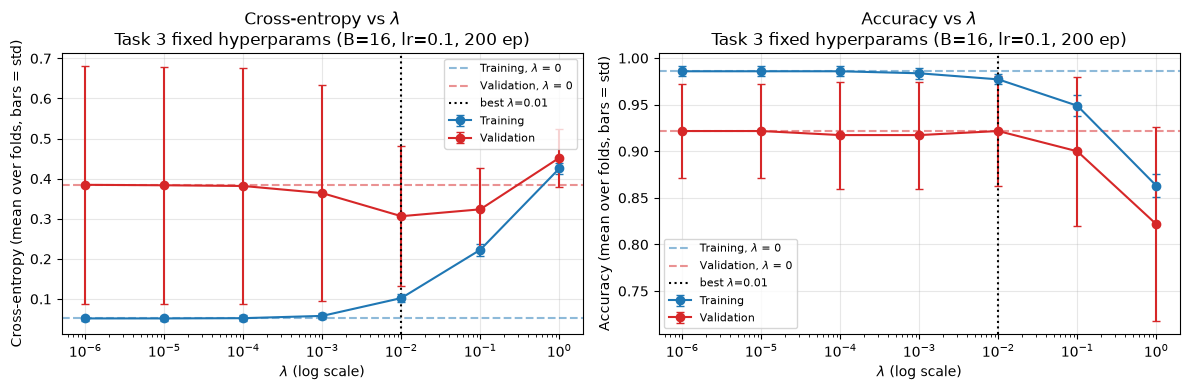

,lam,val_ce_mean,val_ce_std,val_acc_mean,val_acc_std,tr_ce_mean,tr_ce_std,tr_acc_mean,tr_acc_std
0,0.0000,0.3838,0.2961,0.9217,0.0507,0.0514,0.0072,0.9859,0.0055
1,0.0000,0.3847,0.2961,0.9217,0.0507,0.0515,0.0072,0.9859,0.0055
2,0.0000,0.3836,0.2955,0.9217,0.0507,0.0515,0.0072,0.9859,0.0055
3,0.0001,0.3818,0.2935,0.9174,0.0574,0.0521,0.0072,0.9859,0.0055
4,0.0010,0.3640,0.2691,0.9174,0.0574,0.0578,0.0075,0.9837,0.0060
5,0.0100,0.3065,0.1748,0.9217,0.0593,0.1022,0.0091,0.9772,0.0053
6,0.1000,0.3236,0.1019,0.9000,0.0797,0.2227,0.0143,0.9489,0.0112
7,1.0000,0.4520,0.0720,0.8217,0.1042,0.4254,0.0139,0.8630,0.0126


[Task 3 fixed hyperparams (B=16, lr=0.1, 200 ep)] best lambda by CV validation CE: 0.01


Task 2 best (B=64, lr=0.1, 200 ep):   0%|          | 0/8 [00:00<?, ?it/s]

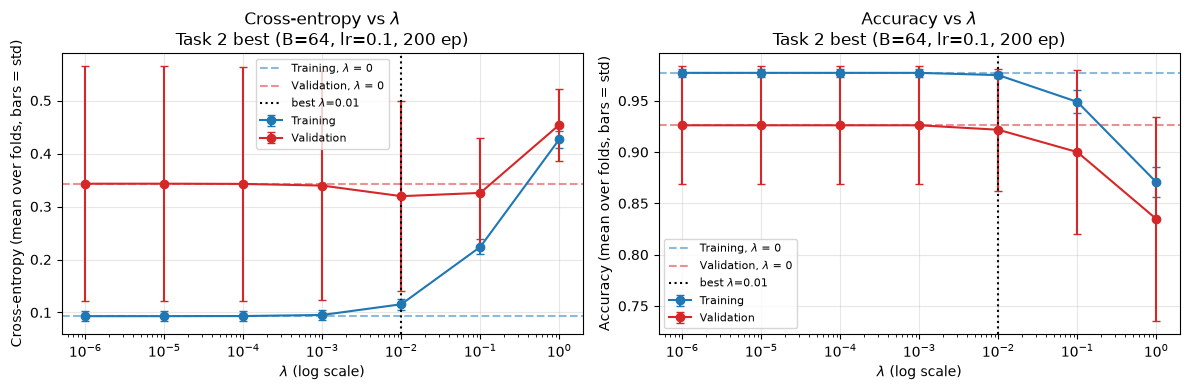

,lam,val_ce_mean,val_ce_std,val_acc_mean,val_acc_std,tr_ce_mean,tr_ce_std,tr_acc_mean,tr_acc_std
0,0.0000,0.3429,0.2219,0.9261,0.0577,0.0931,0.0097,0.9772,0.0041
1,0.0000,0.3430,0.2218,0.9261,0.0577,0.0931,0.0097,0.9772,0.0041
2,0.0000,0.3431,0.2219,0.9261,0.0577,0.0931,0.0097,0.9772,0.0041
3,0.0001,0.3427,0.2213,0.9261,0.0577,0.0933,0.0097,0.9772,0.0041
4,0.0010,0.3395,0.2164,0.9261,0.0577,0.0953,0.0097,0.9772,0.0041
5,0.0100,0.3195,0.1796,0.9217,0.0593,0.1156,0.0100,0.9750,0.0027
6,0.1000,0.3257,0.1035,0.9000,0.0797,0.2238,0.0143,0.9489,0.0112
7,1.0000,0.4543,0.0684,0.8348,0.0997,0.4269,0.0156,0.8707,0.0147


[Task 2 best (B=64, lr=0.1, 200 ep)] best lambda by CV validation CE: 0.01


,config,lam,train_ce,train_acc,test_ce,test_acc
0,"Task 3 fixed hyperparams (B=16, lr=0.1, 200 ep)",0.01,0.1115,0.9783,0.3759,0.9009
1,"Task 2 best (B=64, lr=0.1, 200 ep)",0.01,0.1202,0.9739,0.3439,0.8996


In [17]:
# Sweep lambdas / Plot / Final Test
from tqdm.notebook import tqdm

LAMBDAS = [0, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1]

# 2 Configs for comparison:
# (Optional). Run the same experiment with the best hyper parameters
# you found in Task 2, and compare your results.
best = get_best_hyperparameters(results)

CFG_A = dict(name="Task 3 fixed hyperparams (B=16, lr=0.1, 200 ep)",
             B=16, lr=0.1, epochs=200, init_scale=0.0) # Config A is the fixed params we need
CFG_B = dict(name=f"Task 2 best (B={best['B']}, lr={best['lr']:g}, {best['epochs']} ep)",
             B=best["B"], lr=best["lr"], epochs=best["epochs"],
              init_scale=best["init_scale"]) # Config B is the best params

def lambda_sweep(x, y, k_folds, lams, cfg):
  rows = []
  for lam in tqdm(lams, desc=cfg["name"]):
    r = cross_validate_with_train(x, y, k_folds, cfg["lr"], lam, cfg["B"],
                            cfg["epochs"], cfg["init_scale"])
    rows.append({"lam": lam, **r})
  return pd.DataFrame(rows)

def plot_sweep(df, cfg, best_lam=None):
  fig, axes = plt.subplots(1, 2, figsize=(12, 4))
  # two panels side by side; left: cross entropy and right: accuracy
  pos = df[df.lam > 0] # log axis can't show lambda = 0 (draw it as dashed lines)

  # the lambda = 0 row (or None if the sweep didn't include 0)
  zero = df[df.lam == 0].iloc[0] if (df.lam == 0).any() else None
  # grab the lambda = 0 row if it exists basically

  for ax, metric, ylab in [(axes[0], "ce", "Cross-entropy"), (axes[1], "acc", "Accuracy")]:
    # draw the training curve in blue and validation curve in red
    for split, color in [("tr", "tab:blue"), ("val", "tab:red")]:
      label = "Training" if split == "tr" else "Validation"
      ax.errorbar(pos.lam, pos[f"{split}_{metric}_mean"], yerr=pos[f"{split}_{metric}_std"],
                  marker="o", capsize=3, color=color, label=label)

      # lambda = 0 as a low opacity dashed horizontal line
      if  zero is not None:
        ax.axhline(zero[f"{split}_{metric}_mean"], ls="--", color=color,
                   alpha=0.5, label=f"{label}, $\\lambda$ = 0")
    # dotted vert line at CV-selected lambda
    if best_lam is not None and best_lam > 0:
      ax.axvline(best_lam, ls=":", color="k", label=f"best $\\lambda$={best_lam:g}")

    # cosmetics
    ax.set_xscale("log")
    ax.set_xlabel("$\\lambda$ (log scale)") # $.$ renders the greek letter
    ax.set_ylabel(ylab + " (mean over folds, bars = std)")
    ax.set_title(f"{ylab} vs $\\lambda$\n{cfg['name']}")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

  plt.tight_layout()
  plt.show()



def final_test_eval(x_tr_raw, y_tr, x_te_raw, y_te, lam, cfg):
  """Retrain on all training data with chosen lambda, evaluate once on test set."""
  s = Standardizer()
  s.fit(x_tr_raw) # mean/std from all training samples
  s.std[s.std == 0] = 1.0 # protect constant features to avoid dividing by zero
  # standardize training and test features
  x_tr, x_te = s.standardize(x_tr_raw), s.standardize(x_te_raw)

  # train final model on the whole (training+validation) set using chosen lam
  model = LogisticRegression(lam, init_scale=cfg["init_scale"])
  model.fit(x_tr, y_tr, StochasticGradientDescent(cfg["B"], cfg["lr"],
                                                    cfg["epochs"], logging=False))
  # cfg[...] pull the batch size, learning rate, and epochs

  # eval the trained weights on both sets and return the results as dict
  return {
      "config": cfg["name"], "lam": lam, # which setup produced these numbers
      "train_ce": model.calculate_crossentropy(x_tr, y_tr, model.w), # train CE (no lam penalty)
      "train_acc": model.calculate_accuracy(x_tr, y_tr, model.w), # train accuracy
      "test_ce": model.calculate_crossentropy(x_te, y_te, model.w), # test ce (reported result)
      "test_acc": model.calculate_accuracy(x_te, y_te, model.w) # test accuracy (reported result)
    }


sweeps, best_lams, test_rows = {}, {}, []
for cfg in [CFG_A, CFG_B]:
  df = lambda_sweep(x_train, y_train, folds, LAMBDAS, cfg)
  best_lam = df.loc[df.val_ce_mean.idxmin(), "lam"]
  sweeps[cfg["name"]], best_lams[cfg["name"]] = df, best_lam
  plot_sweep(df, cfg, best_lam)
  display(df.round(4))
  print(f"[{cfg['name']}] best lambda by CV validation CE: {best_lam:g}")

  test_rows.append(final_test_eval(x_train, y_train, x_test, y_test, best_lam, cfg))

pd.DataFrame(test_rows).round(4)




dataset size:   0%|          | 0/4 [00:00<?, ?it/s]

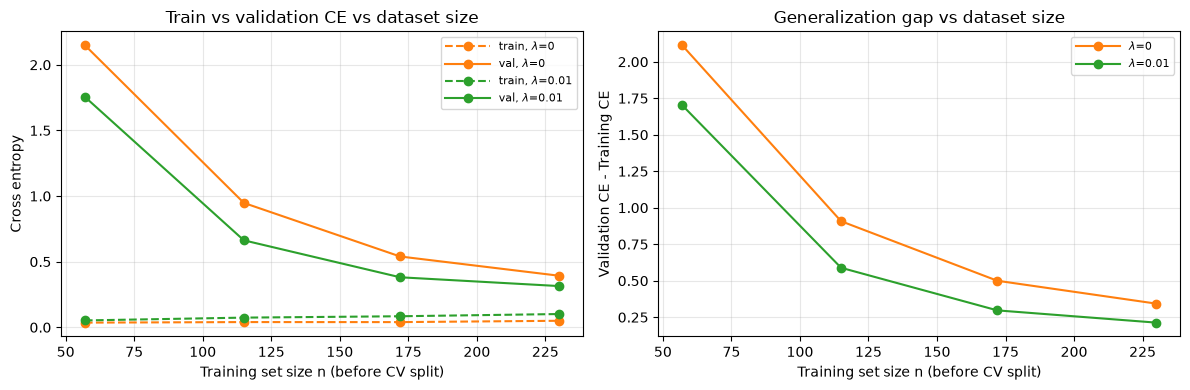

,n,lam,val_ce_mean,val_ce_std,val_acc_mean,val_acc_std,tr_ce_mean,tr_ce_std,tr_acc_mean,tr_acc_std,ce_gap
0,57,0.00,2.1493,3.8856,0.8591,0.0726,0.0357,0.0121,0.9912,0.0108,2.1135
1,57,0.01,1.7556,3.0320,0.8409,0.0691,0.0525,0.0128,0.9869,0.0107,1.7031
2,115,0.00,0.9478,0.7406,0.8696,0.0476,0.0399,0.0055,0.9957,0.0053,0.9079
3,115,0.01,0.6628,0.4592,0.8696,0.0728,0.0738,0.0055,0.9891,0.0069,0.5889
4,172,0.00,0.5397,0.3836,0.8894,0.0224,0.0397,0.0035,0.9913,0.0029,0.5000
5,172,0.01,0.3812,0.2220,0.8953,0.0399,0.0843,0.0025,0.9826,0.0035,0.2970
6,230,0.00,0.3930,0.1915,0.9087,0.0443,0.0498,0.0062,0.9826,0.0053,0.3432
7,230,0.01,0.3143,0.1347,0.9087,0.0443,0.1012,0.0066,0.9772,0.0063,0.2131


In [18]:
# (optional) effect of training set size
"""Optionally, you may additionally study the regularization effect of dataset
size. As one increases the training set, overfitting is expected to reduce due
to lower variance."""

FRACS = [0.25, 0.5, 0.75, 1.0] # fraction of training set to use
SIZE_LAMS = [0, best_lams[CFG_A["name"]]] # unreg. vs CV selected lam
cfg=CFG_A

N = x_train.shape[0]
perm = rng.permutation(N) # shuffle the training set
size_rows = [] #one dict per (size, lam) combination
for frac in tqdm(FRACS, desc="dataset size"):
  n = int(frac * N) # number of samples at this size
  sub = perm[:n] # first n of the SAME permutation
  # smaller sets are subsets of bigger ones so sizes are comparable

  xs, ys = x_train[sub], y_train[sub]
  f = list(kfold(n, 5, rng)) # fresh 5 folds spliut of just these n

  for lam in SIZE_LAMS: # run CV at this size for each lam
    r = cross_validate_with_train(xs, ys, f, cfg["lr"], lam, cfg["B"],
                                  cfg["epochs"], cfg["init_scale"])
    size_rows.append({"n": n, "lam": lam, **r})

size_df = pd.DataFrame(size_rows)
size_df["ce_gap"] = size_df.val_ce_mean - size_df.tr_ce_mean # protect against overfitting

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# one color per lam; solid means validation, dashed means training
for lam, color in zip(SIZE_LAMS, ["tab:orange", "tab:green"]):
  d = size_df[size_df.lam == lam] # rows for this lam only
  axes[0].plot(d.n, d.tr_ce_mean, "--o", color=color, label=f"train, $\\lambda$={lam:g}")
  axes[0].plot(d.n, d.val_ce_mean, "-o", color=color, label=f"val, $\\lambda$={lam:g}")
  axes[1].plot(d.n, d.ce_gap, "-o", color=color, label=f"$\\lambda$={lam:g}")

# left labels
axes[0].set_xlabel("Training set size n (before CV split)"); axes[0].set_ylabel("Cross entropy")
axes[0].set_title("Train vs validation CE vs dataset size")
# right labels
axes[1].set_xlabel("Training set size n (before CV split)"); axes[1].set_ylabel("Validation CE - Training CE")
axes[1].set_title("Generalization gap vs dataset size")

for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, handlelength=4)
plt.tight_layout(); plt.show()
size_df.round(4)

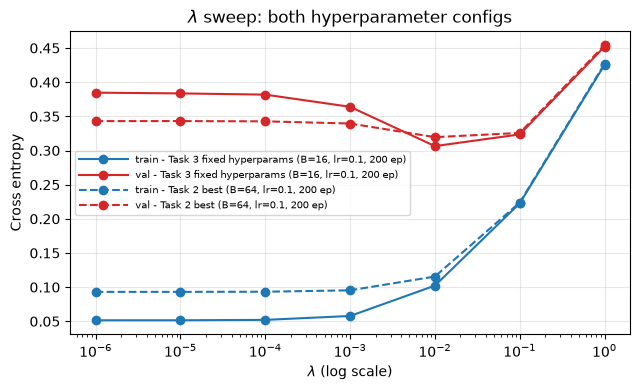

In [19]:
# (optional) side by side comparison of the 2 configs (default vs Task 2 best)

cmp = pd.concat(
    [sweeps[c["name"]].assign(config=c["name"]) for c in (CFG_A, CFG_B)], ignore_index = True
)

fig, ax = plt.subplots(figsize=(6.5, 4))

# groupby splits cmp into 1 sub table per config
# zip pairs each group with a line style; solid for first config, dashed for second config
for (name, d), ls in zip(cmp.groupby("config", sort=False), ["-", "--"]):
    d = d[d.lam > 0] # drop lam = 0 bcs can't be placed on log axis

    # blue is training CE, red is validation CE (line style tells you which config as stated above)
    ax.plot(d.lam, d.tr_ce_mean, ls, color="tab:blue", marker="o", label=f"train - {name}")
    ax.plot(d.lam, d.val_ce_mean, ls, color="tab:red", marker="o", label=f"val - {name}")

# Cosmetics and readability
ax.set_xscale("log")
ax.set_xlabel("$\\lambda$ (log scale)")
ax.set_ylabel("Cross entropy")
ax.set_title("$\\lambda$ sweep: both hyperparameter configs")
ax.grid(alpha=0.3)
ax.legend(fontsize=7, handlelength=5)
plt.tight_layout()
plt.show()



# Task 4: L1-Regularized Logistic Regression and the Regularization Path (Using scikit-learn)

In [20]:
s4 = Standardizer()
s4.fit(x_train)
x_train_s = s4.standardize(x_train)

Cs = np.logspace(-2, 0, 30)
w_list = []
for C in Cs:
  l = sklearn.linear_model.LogisticRegression(penalty="l1", C=C, solver="saga", max_iter=5000)
  l.fit(x_train_s, y_train)
  w_list.append(l.coef_.flatten())
ws = np.column_stack(w_list)

/Users/ethan/misc/comp551/ML-Logistic/venv/lib/python3.15/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/ethan/misc/comp551/ML-Logistic/venv/lib/python3.15/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Users/ethan/misc/comp551/ML-Logistic/venv/lib/python3.15/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value

Text(0, 0.5, 'Coefficient Value')

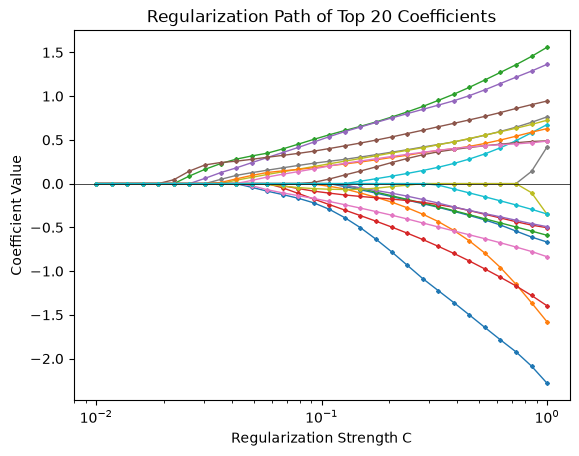

In [21]:
k = 20

top_k = ws[(-np.abs(ws[:, 29])).argsort()[:k]]

for i in range(top_k.shape[0]):
  plt.plot(Cs, top_k[i], "-D", lw=1.0, ms=2.0)

plt.xscale('log')
plt.axhline(y=0, lw=0.5, color="k")
plt.title(f"Regularization Path of Top {k} Coefficients")
plt.xlabel("Regularization Strength C")
plt.ylabel("Coefficient Value")

Text(0, 0.5, 'Number of Non-Zero Coefficients')

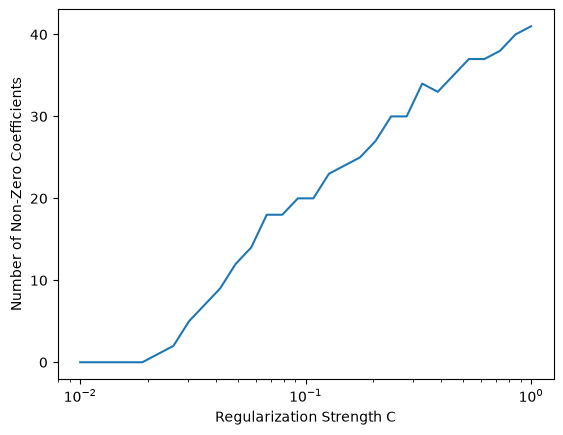

In [22]:
sparsity = (ws != 0).sum(axis=0)
plt.plot(Cs, sparsity)
plt.xscale('log')
plt.xlabel("Regularization Strength C") # C = 1/lambda
plt.ylabel("Number of Non-Zero Coefficients")

In [23]:
l_cv = sklearn.linear_model.LogisticRegressionCV(penalty="l1", Cs=Cs, cv=5, solver="saga", max_iter=2000)
l_cv.fit(x_train, y_train)

/Users/ethan/misc/comp551/ML-Logistic/venv/lib/python3.15/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/Users/ethan/misc/comp551/ML-Logistic/venv/lib/python3.15/site-packages/sklearn/linear_model/_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.warn(
/Users/ethan/misc/comp551/ML-Logistic/venv/lib/python3.15/site-packages/sklearn/linear_

,"Cs Cs: int or list of floats, default=10Each of the values in Cs describes the inverse of regularizationstrength. If Cs is as an int, then a grid of Cs values are chosenin a logarithmic scale between 1e-4 and 1e4.Like in support vector machines, smaller values specify strongerregularization.","array([0.01 ..., 1. ])"
,"cv cv: int or cross-validation generator, default=NoneThe default cross-validation generator used is Stratified K-Folds.If an integer is provided, it specifies the number of folds, `n_folds`, used.See the module :mod:`sklearn.model_selection` module for thelist of possible cross-validation objects... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"penalty penalty: {'l1', 'l2', 'elasticnet'}, default='l2'Specify the norm of the penalty:- `'l2'`: add an L2 penalty term (used by default);- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'l1'
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' might be slower in :class:`LogisticRegressionCV` because it does not handle warm-starting.- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) chosen and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'saga'
,"max_iter max_iter: int, default=100Maximum number of iterations of the optimization algorithm.",2000
,"l1_ratios l1_ratios: array-like of shape (n_l1_ratios), default=NoneFloats between 0 and 1 passed as Elastic-Net mixing parameter (scaling betweenL1 and L2 penalties). For `l1_ratio = 0` the penalty is an L2 penalty. For`l1_ratio = 1` it is an L1 penalty. For 

Text(0, 0.5, 'Cross-Validation Accuracy')

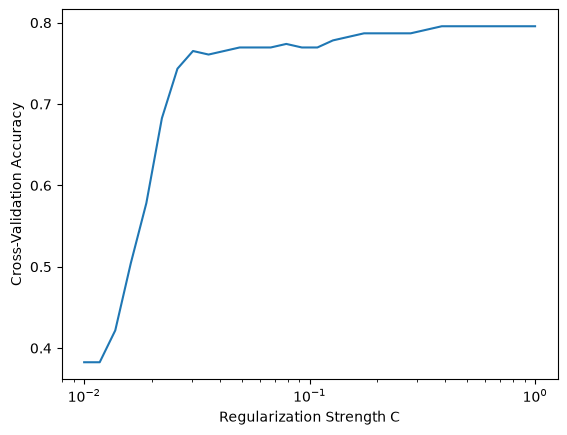

In [24]:
accs = l_cv.scores_[np.int64(1)].mean(axis=0)
plt.plot(Cs, accs)
plt.xscale('log')
plt.xlabel("Regularization Strength C")
plt.ylabel("Cross-Validation Accuracy")